In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [10]:
import pandas as pd

df = pd.read_csv('/content/insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


**EDA**

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [12]:
df.shape

(1338, 7)

In [13]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [14]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

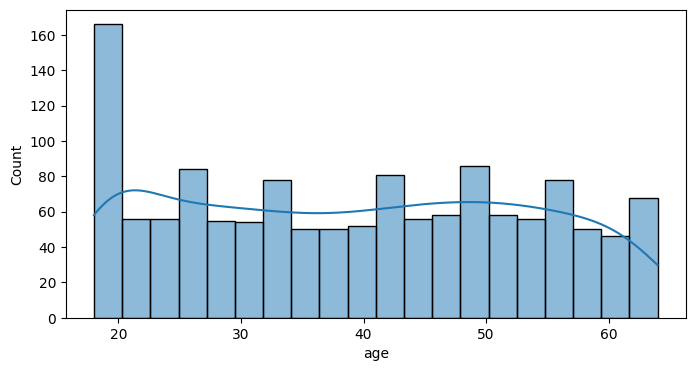

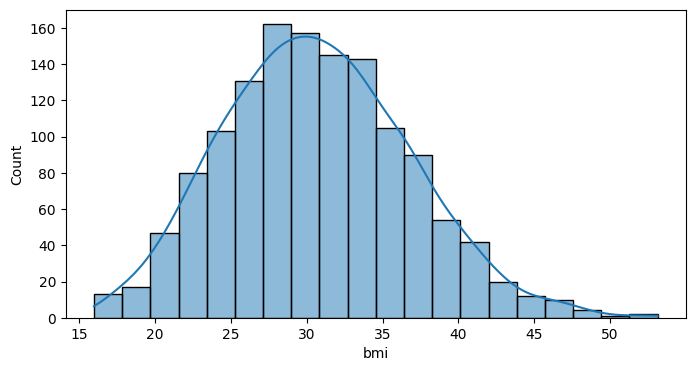

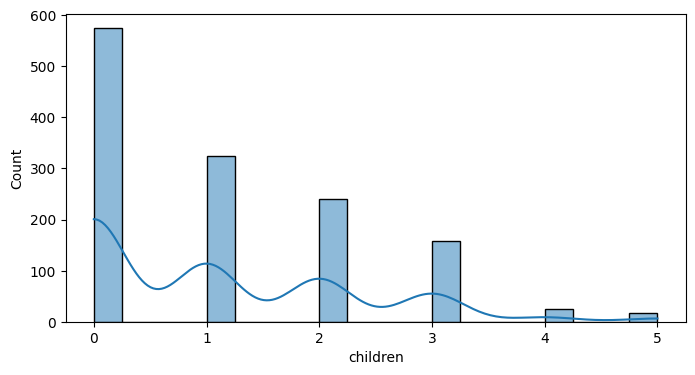

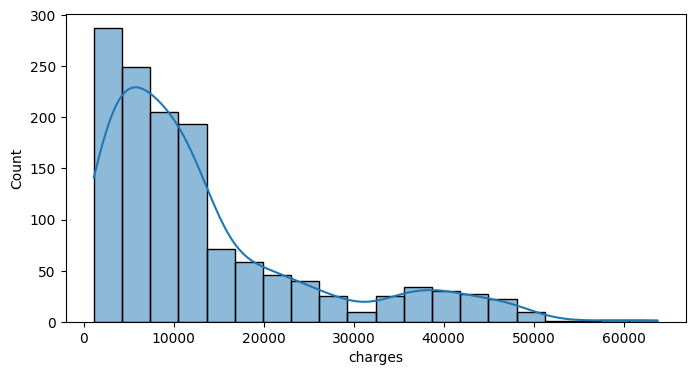

In [15]:
numeric_data = ['age', 'bmi', 'children', 'charges']
for col in numeric_data:
    plt.figure(figsize =(8,4))
    sns.histplot(df[col],kde = True , bins =20)

<Axes: xlabel='sex', ylabel='count'>

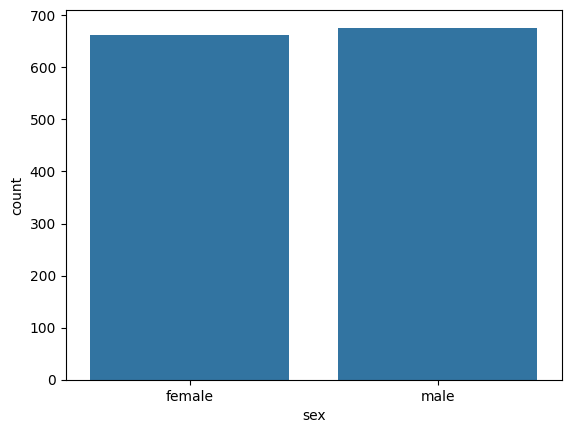

In [16]:
sns.countplot(x = df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

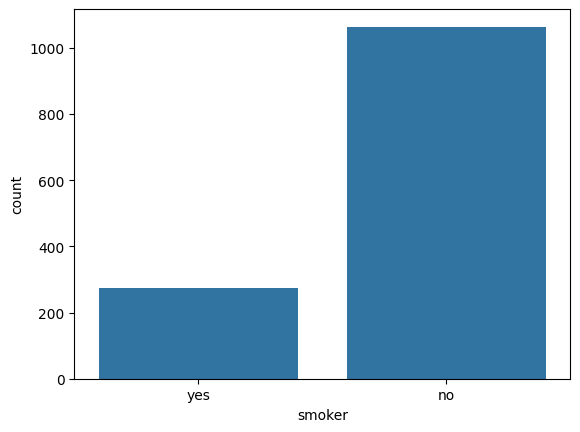

In [17]:
sns.countplot(x = df['smoker'])

<Axes: xlabel='region', ylabel='count'>

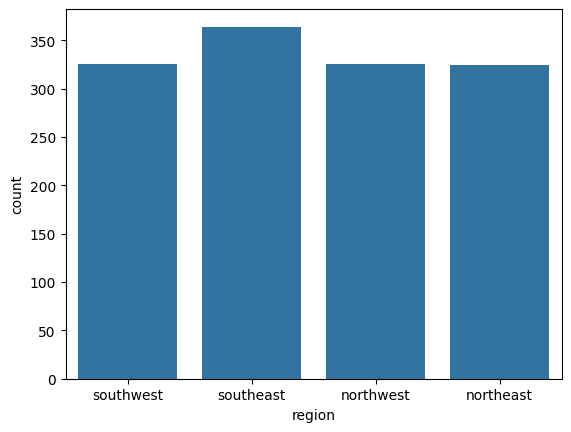

In [18]:
sns.countplot(x = df['region'])

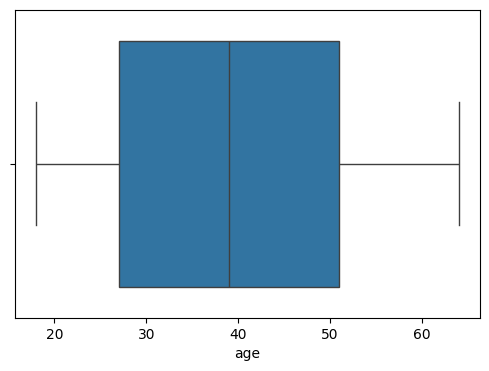

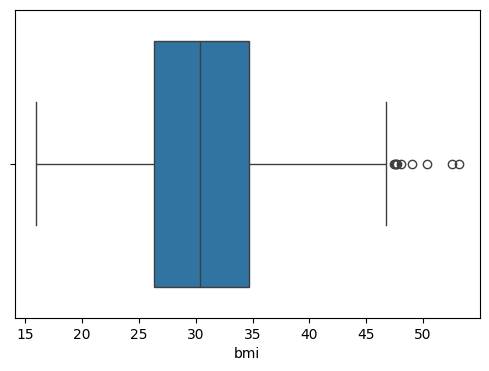

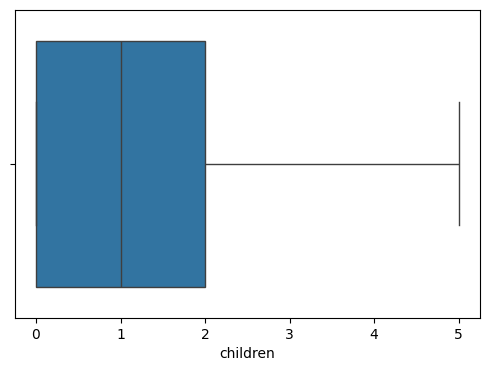

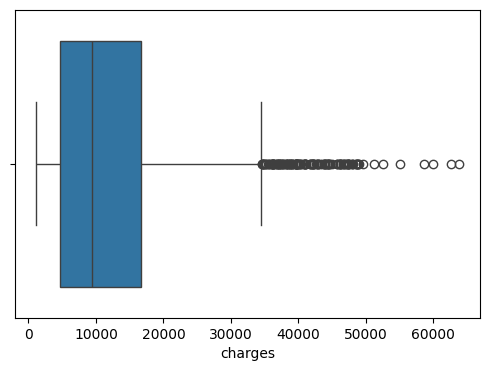

In [19]:
for col in numeric_data:
    plt.figure(figsize = (6,4))
    sns.boxplot(x= df[col])

<Axes: >

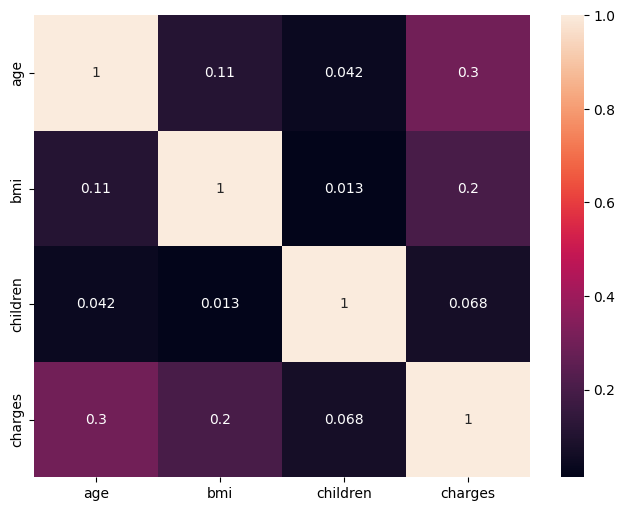

In [20]:
plt.figure (figsize = (8,6))
sns.heatmap(df.corr(numeric_only = True), annot =True)

**Data Cleaning and Preprocessing**

In [21]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [22]:
df.duplicated().sum()

np.int64(1)

In [23]:
df.drop_duplicates(inplace = True)


In [24]:
df.shape

(1337, 7)

In [25]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [26]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [27]:
df.dtypes

,0
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


In [28]:
df['sex'].value_counts()

,count
sex,
male,675
female,662


In [29]:
df['sex'] = df['sex'].map({'male' : 0, 'female' : 1})

In [30]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [31]:
df['smoker'].value_counts()

,count
smoker,
no,1063
yes,274


In [32]:
df['smoker'] = df['smoker'].map({'yes' : 1, 'no' : 0})

In [33]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [34]:
df.rename(columns = {
    'sex' : 'is_female',
    'smoker' : 'is_smoker'
},inplace = True)

In [35]:
df.head()

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [36]:
df.dtypes

,0
age,int64
is_female,int64
bmi,float64
children,int64
is_smoker,int64
region,object
charges,float64


In [37]:
df['region'].value_counts()

,count
region,
southeast,364
southwest,325
northwest,324
northeast,324


In [38]:
df = pd.get_dummies(df,columns =['region'])

In [39]:
df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,False,True
1,18,0,33.770,1,0,1725.55230,False,False,True,False
2,28,0,33.000,3,0,4449.46200,False,False,True,False
3,33,0,22.705,0,0,21984.47061,False,True,False,False
4,32,0,28.880,0,0,3866.85520,False,True,False,False


In [40]:
df = df.astype(int)

In [41]:
df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,0,1
1,18,0,33,1,0,1725,0,0,1,0
2,28,0,33,3,0,4449,0,0,1,0
3,33,0,22,0,0,21984,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0


**Features Enginering and Extraction**

<Axes: xlabel='bmi', ylabel='Count'>

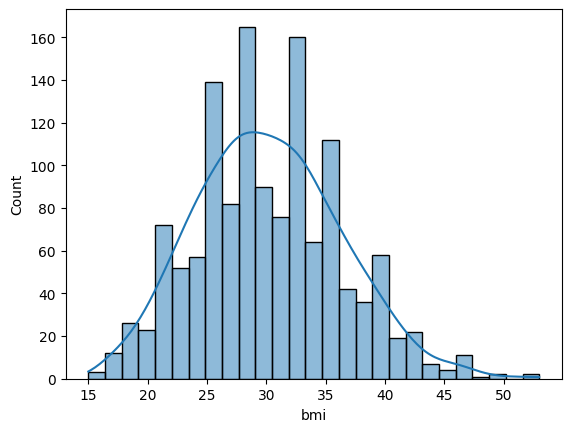

In [42]:
sns.histplot(df['bmi'],kde = True)

In [43]:
df['bmi_category'] = pd.cut(
    df['bmi'],
    bins=[0, 18.5, 25, 30, float('inf')],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese'],
    right=False
)

In [44]:
df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27,0,1,16884,0,0,0,1,Overweight
1,18,0,33,1,0,1725,0,0,1,0,Obese
2,28,0,33,3,0,4449,0,0,1,0,Obese
3,33,0,22,0,0,21984,0,1,0,0,Normal
4,32,0,28,0,0,3866,0,1,0,0,Overweight


In [45]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 25, 40, 55, 100],
    labels=['Young', 'Adult', 'Middle_Aged', 'Senior'],
    right=False
)

In [46]:
df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category,age_group
0,19,1,27,0,1,16884,0,0,0,1,Overweight,Young
1,18,0,33,1,0,1725,0,0,1,0,Obese,Young
2,28,0,33,3,0,4449,0,0,1,0,Obese,Adult
3,33,0,22,0,0,21984,0,1,0,0,Normal,Adult
4,32,0,28,0,0,3866,0,1,0,0,Overweight,Adult


In [47]:
df['age_group'].value_counts()

,count
age_group,
Middle_Aged,422
Adult,396
Young,277
Senior,242


In [48]:
df = pd.get_dummies(df,columns =['bmi_category'])

In [49]:
df = pd.get_dummies(df,columns =['age_group'])

In [50]:
df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,age_group_Young,age_group_Adult,age_group_Middle_Aged,age_group_Senior
0,19,1,27,0,1,16884,0,0,0,1,False,False,True,False,True,False,False,False
1,18,0,33,1,0,1725,0,0,1,0,False,False,False,True,True,False,False,False
2,28,0,33,3,0,4449,0,0,1,0,False,False,False,True,False,True,False,False
3,33,0,22,0,0,21984,0,1,0,0,False,True,False,False,False,True,False,False
4,32,0,28,0,0,3866,0,1,0,0,False,False,True,False,False,True,False,False


In [51]:
# Interaction features
df["bmi_smoker"] = df["bmi"] * df["is_smoker"]
df["age_smoker"] = df["age"] * df["is_smoker"]

# Nonlinear features
df["age_squared"] = df["age"] ** 2
df["bmi_squared"] = df["bmi"] ** 2

In [52]:
df = df.astype(int)

In [53]:
df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,...,bmi_category_Overweight,bmi_category_Obese,age_group_Young,age_group_Adult,age_group_Middle_Aged,age_group_Senior,bmi_smoker,age_smoker,age_squared,bmi_squared
0,19,1,27,0,1,16884,0,0,0,1,...,1,0,1,0,0,0,27,19,361,729
1,18,0,33,1,0,1725,0,0,1,0,...,0,1,1,0,0,0,0,0,324,1089
2,28,0,33,3,0,4449,0,0,1,0,...,0,1,0,1,0,0,0,0,784,1089
3,33,0,22,0,0,21984,0,1,0,0,...,0,0,0,1,0,0,0,0,1089,484
4,32,0,28,0,0,3866,0,1,0,0,...,1,0,0,1,0,0,0,0,1024,784


In [54]:
%pip install scikit-learn

In [55]:
from sklearn.preprocessing import StandardScaler
cols = ['age','bmi','children','bmi_smoker','age_smoker','age_squared','bmi_squared']
scaler = StandardScaler()

df[cols] = scaler.fit_transform(df[cols])

In [56]:
df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,...,bmi_category_Overweight,bmi_category_Obese,age_group_Young,age_group_Adult,age_group_Middle_Aged,age_group_Senior,bmi_smoker,age_smoker,age_squared,bmi_squared
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0,1,...,1,0,1,0,0,0,1.662643,0.662255,-1.221599,-0.570581
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,...,0,1,1,0,0,0,-0.494246,-0.470625,-1.254484,0.368781
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,...,0,1,0,1,0,0,-0.494246,-0.470625,-0.845647,0.368781
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,1,0,0,...,0,0,0,1,0,0,-0.494246,-0.470625,-0.574570,-1.209869
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,0,...,1,0,0,1,0,0,-0.494246,-0.470625,-0.632340,-0.427067


In [57]:
%pip install scipy

**Selected Features**

In [58]:
from scipy.stats import pearsonr

selected_features = ['age', 'is_female', 'bmi', 'children', 'is_smoker',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese', 'age_group_Young',
       'age_group_Adult', 'age_group_Middle_Aged', 'age_group_Senior','bmi_smoker'	,'age_smoker',	'age_squared',	'bmi_squared']

In [59]:
corr = {features : pearsonr(df[features],df['charges'])[0]

for features in selected_features
               }
corr_df = pd.DataFrame(list(corr.items()),columns = ['Features' , 'Pearson corr'])
corr_df = corr_df.sort_values(by ='Pearson corr',ascending=False)

corr_df

,Features,Pearson corr
17,bmi_smoker,0.845721
18,age_smoker,0.789252
4,is_smoker,0.787234
19,age_squared,0.300166
0,age,0.298309
16,age_group_Senior,0.203261
12,bmi_category_Obese,0.200348
2,bmi,0.196236
20,bmi_squared,0.190438
15,age_group_Middle_Aged,0.109786


In [60]:
from scipy.stats import chi2_contingency
import pandas as pd

cat_features = ['is_female','is_smoker','region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese', 'age_group_Young',
       'age_group_Adult', 'age_group_Middle_Aged', 'age_group_Senior','bmi_smoker'	,'age_smoker',	'age_squared',	'bmi_squared']
alpha = 0.05
df['charges_bin'] = pd.qcut(df['charges'], q=4)



results = []

for col in cat_features:
    contingency_table = pd.crosstab(df[col], df['charges_bin'])

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    results.append({
        'Feature': col,
        'Chi-square': chi2,
        'p-value': p_value,
        'Decision': 'Reject Null(Keep Feature)'
        if p_value < alpha else 'Accept Null (drop Feature)'
    })

chi2_df = pd.DataFrame(results)

chi2_df = chi2_df.sort_values(
    by='p-value',
    ascending=True
)

chi2_df


,Feature,Chi-square,p-value,Decision
16,age_squared,1509.130250,4.230603e-229,Reject Null(Keep Feature)
1,is_smoker,848.219178,1.507478e-183,Reject Null(Keep Feature)
14,bmi_smoker,911.635397,4.350577e-133,Reject Null(Keep Feature)
15,age_smoker,888.392616,1.030516e-108,Reject Null(Keep Feature)
13,age_group_Senior,446.231518,2.136718e-96,Reject Null(Keep Feature)
10,age_group_Young,396.580021,1.218818e-85,Reject Null(Keep Feature)
12,age_group_Middle_Aged,252.766498,1.649910e-54,Reject Null(Keep Feature)
11,age_group_Adult,161.439086,8.965156e-35,Reject Null(Keep Feature)
4,region_southeast,15.998167,1.134966e-03,Reject Null(Keep Feature)
0,is_female,10.258784,1.648974e-02,Reject Null(Keep Feature)


In [61]:
df.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese', 'age_group_Young',
       'age_group_Adult', 'age_group_Middle_Aged', 'age_group_Senior',
       'bmi_smoker', 'age_smoker', 'age_squared', 'bmi_squared',
       'charges_bin'],
      dtype='object')

In [62]:
final_df=df[['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
        'region_southeast',
        'bmi_category_Obese', 'age_group_Young',
       'age_group_Adult', 'age_group_Middle_Aged', 'age_group_Senior',
       'bmi_smoker', 'age_smoker', 'age_squared', 'bmi_squared']


                     ]

In [63]:
final_df

,age,is_female,bmi,children,is_smoker,charges,region_southeast,bmi_category_Obese,age_group_Young,age_group_Adult,age_group_Middle_Aged,age_group_Senior,bmi_smoker,age_smoker,age_squared,bmi_squared
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,1,0,0,0,1.662643,0.662255,-1.221599,-0.570581
1,-1.511647,0,0.462463,-0.079442,0,1725,1,1,1,0,0,0,-0.494246,-0.470625,-1.254484,0.368781
2,-0.799350,0,0.462463,1.580143,0,4449,1,1,0,1,0,0,-0.494246,-0.470625,-0.845647,0.368781
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,0,0,1,0,0,-0.494246,-0.470625,-0.574570,-1.209869
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,0,0,1,0,0,-0.494246,-0.470625,-0.632340,-0.427067
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,0,10600,0,1,0,0,1,0,-0.494246,-0.470625,0.679495,-0.124384
1334,-1.511647,1,0.135659,-0.909234,0,2205,0,1,1,0,0,0,-0.494246,-0.470625,-1.254484,0.034786
1335,-1.511647,1,0.952670,-0.909234,0,1629,1,1,1,0,0,0,-0.494246,-0.470625,-1.254484,0.908915
1336,-1.297958,1,-0.844753,-0.909234,0,2007,0,0,1,0,0,0,-0.494246,-0.470625,-1.150497,-0.841952


In [64]:
df

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,...,bmi_category_Obese,age_group_Young,age_group_Adult,age_group_Middle_Aged,age_group_Senior,bmi_smoker,age_smoker,age_squared,bmi_squared,charges_bin
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0,1,...,0,1,0,0,0,1.662643,0.662255,-1.221599,-0.570581,"(16657.0, 63770.0]"
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,...,1,1,0,0,0,-0.494246,-0.470625,-1.254484,0.368781,"(1120.999, 4746.0]"
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,...,1,0,1,0,0,-0.494246,-0.470625,-0.845647,0.368781,"(1120.999, 4746.0]"
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,1,0,0,...,0,0,1,0,0,-0.494246,-0.470625,-0.574570,-1.209869,"(16657.0, 63770.0]"
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,0,...,0,0,1,0,0,-0.494246,-0.470625,-0.632340,-0.427067,"(1120.999, 4746.0]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,0,10600,0,1,0,0,...,1,0,0,1,0,-0.494246,-0.470625,0.679495,-0.124384,"(9386.0, 16657.0]"
1334,-1.511647,1,0.135659,-0.909234,0,2205,1,0,0,0,...,1,1,0,0,0,-0.494246,-0.470625,-1.254484,0.034786,"(1120.999, 4746.0]"
1335,-1.511647,1,0.952670,-0.909234,0,1629,0,0,1,0,...,1,1,0,0,0,-0.494246,-0.470625,-1.254484,0.908915,"(1120.999, 4746.0]"
1336,-1.297958,1,-0.844753,-0.909234,0,2007,0,0,0,1,...,0,1,0,0,0,-0.494246,-0.470625,-1.150497,-0.841952,"(1120.999, 4746.0]"


In [65]:
from sklearn.model_selection import train_test_split

In [66]:
x = final_df.drop('charges',axis = 1)
y = final_df['charges']

In [67]:
X_train, X_test, y_train, y_test = train_test_split  (x, y, test_size=0.20, random_state=42)

In [68]:
from sklearn.linear_model import LinearRegression

In [69]:
model = LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [70]:
from sklearn.metrics import r2_score

# Predict values
y_pred = model.predict(X_test)

# Calculate R-squared
r2 = r2_score(y_test, y_pred)

# Calculate Adjusted R-squared
n = X_test.shape[0]  # Number of test samples
p = X_test.shape[1]  # Number of independent variables

adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

print("R-squared:", r2)
print("Adjusted R-squared:", adjusted_r2)

R-squared: 0.8828258371227791
Adjusted R-squared: 0.8758511845705635
